# SHI — UET PM2.5: ARIMA (hourly) and satellite/weather models (daily)

**Part A (Steps 1–8)** — the original hourly ARIMA + Fourier notebook, with fixes:
- workbooks are now read from `data/raw/pm25/`;
- the ARIMA order is chosen by AIC on the **training part only** (before, `auto_arima` saw the whole series, including the test hours);
- `pmdarima` is no longer needed (it is not installed in this Python 3.13 kernel);
- results go to `data/processed/shi_hourly/`.

**Part B (Steps B1–B9)** — new: daily UET PM2.5 together with the new raw datasets
(MERRA-2 aerosol + meteorology, MODIS MCD19A2 AOD, TROPOMI aerosol index), compared on the same test days:
ARIMA, Seasonal ARIMA (7 days), ARIMA + satellite/weather inputs (ARIMAX), a "today = yesterday" baseline,
and Linear / RandomForest / XGBoost models that **do not** use yesterday's PM2.5.

### Install (run once, only if the next cell says a package is missing)
`%pip` installs into **this notebook's** Python (3.13). The old cells used `!python -m pip`, which installed into a different Python (3.10).

In [ ]:
%pip install -q numpy pandas openpyxl statsmodels matplotlib scikit-learn xgboost netCDF4

In [ ]:
# ===== 1. Imports, dependency check =====
import sys, os, re, time, json, hashlib, warnings, itertools, importlib.util
import datetime as dt
from pathlib import Path

_REQUIRED = ["numpy", "pandas", "openpyxl", "statsmodels", "matplotlib", "sklearn", "xgboost", "netCDF4"]
_missing = [m for m in _REQUIRED if importlib.util.find_spec(m) is None]
if _missing:
    raise ImportError(
        "Missing packages: " + ", ".join(_missing) + "\nRun the install cell above, or:\n\n"
        f"    {sys.executable} -m pip install " + " ".join(_missing)
    )

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from IPython.display import display

In [ ]:
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 120)

_T0 = time.perf_counter()
def banner(msg):
    """Progress line with wall-clock time and minutes since notebook started."""
    print(f"\n[{time.strftime('%H:%M:%S')} | +{(time.perf_counter() - _T0) / 60:5.1f} min] {msg}", flush=True)

# ---------------- configuration (everything tunable lives here) ----------------
NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT = next((p for p in [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents] if (p / "data" / "raw").is_dir()), None)
assert PROJECT is not None, f"Could not find data/raw in {NOTEBOOK_DIR} or a parent folder"
RAW, INTERIM, PROCESSED = PROJECT / "data" / "raw", PROJECT / "data" / "interim", PROJECT / "data" / "processed"
SEARCH_DIRS = [RAW / "pm25"]              # the three PM2.5 Excel workbooks
OUT_DIR = PROCESSED / "shi_hourly"        # results of Part A
TARGET_STATION = "UET"

# Cleaning rules
MAX_INTERP_GAP_H = 6
SPIKE_MIN = 700.0
SPIKE_RATIO = 5.0
SPIKE_WINDOW_H = 336

# Split (chronological)
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15        # test = remaining 15%

# ARIMA + Fourier
HORIZON = 168               # forecast horizon in hours (7 days)
ALPHA = 0.05                # 95% confidence interval
MAXITER = 200               # optimiser iterations per fit
LOG_TRANSFORM = True        # model log1p(PM2.5); back-transformed to ug/m3
FOURIER_PERIOD = 24         # daily cycle period (hours)
N_HARMONICS = 3             # number of Fourier sin/cos pairs for daily cycle

print("Packages OK. Python", sys.version.split()[0])
print("Project folder:", PROJECT)
print("PM2.5 workbooks searched in:", [str(d) for d in SEARCH_DIRS])
print("Outputs will be written to:", OUT_DIR)

### Step 1/8: locating workbooks

In [16]:
# ===== 2. Step 1/8: locating workbooks =====
banner("Step 1/8: locating workbooks")

SOURCE_ROLES = {
    "Jun-Dec 2025": re.compile(r"jun.*dec", re.I),
    "Jan-Apr 2026": re.compile(r"jan.*apr", re.I),
    "May 2026":     re.compile(r"may.*2026|2026.*may", re.I),
}

def _sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

_candidates = []
for _d in SEARCH_DIRS:
    if _d.is_dir():
        for _p in sorted(_d.iterdir()):
            if _p.suffix.lower() in (".xlsx", ".xlsm") and not _p.name.startswith("~$"):
                _candidates.append(_p)

_registry, _seen = [], {}
for _p in _candidates:
    _role = next((r for r, rx in SOURCE_ROLES.items() if rx.search(_p.stem)), None)
    _digest = _sha256(_p)
    if _role is None:
        _action = "ignored (name does not match a known period)"
    elif (_role, _digest) in _seen:
        _action = f"ignored (byte-identical copy of {_seen[(_role, _digest)]})"
    else:
        _seen[(_role, _digest)] = _p.name
        _action = "USED"
    _registry.append({
        "period": _role, 
        "file": _p.name, 
        "folder": _p.parent.name or ".",
        "size_kb": round(_p.stat().st_size / 1024, 1), 
        "sha256": _digest[:10], 
        "action": _action
    })

registry = pd.DataFrame(_registry)
display(registry)

WORKBOOKS = [(r["period"], next(p for p in _candidates if p.name == r["file"]))
             for r in _registry if r["action"] == "USED"]
_missing_roles = [r for r in SOURCE_ROLES if r not in {w[0] for w in WORKBOOKS}]
if _missing_roles:
    raise FileNotFoundError(f"No workbook found for: {_missing_roles}. Searched: {[str(d) for d in SEARCH_DIRS]}")
print(f"\n{len(WORKBOOKS)} workbooks will be loaded.")


[16:12:30 | +  0.4 min] Step 1/8: locating workbooks


,period,file,folder,size_kb,sha256,action
0,Jan-Apr 2026,"Hourly PM2.5 data from January to April 2026 of 3 districts, Lahore, Gujranwala, and S...",Fast,272.9,927b9eeddf,USED
1,May 2026,"Hourly PM2.5 data from May 2026 of 3 districts Lahore, Gujranwala, and Sheikhupura - C...",Fast,86.5,5c4411a6ec,USED
2,Jun-Dec 2025,PM 2.5 DATA FROM JUNE TO DECEMBER 2025.xlsx,Fast,1125.9,ee26baf510,USED



3 workbooks will be loaded.


### Step 2/8: reading UET columns/sheets 

In [17]:
# ===== 3. Step 2/8: reading UET columns/sheets =====
banner("Step 2/8: reading UET columns/sheets")

EXCEL_EPOCH = pd.Timestamp("1899-12-30")
_UET_RE = re.compile(r"(?<![a-z])uet(?![a-z])", re.I)
_TIME_HEADERS = {"time", "timestamp", "date & time", "date and time", "datetime", "date"}

def parse_one_timestamp(v):
    """Return (Timestamp or NaT, kind). kind in: datetime, excel_serial, text, blank, unparseable."""
    if v is None or (not isinstance(v, str) and pd.isna(v)):
        return pd.NaT, "blank"
    if isinstance(v, (dt.datetime, np.datetime64)):
        return pd.Timestamp(v), "datetime"
    if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool):
        if np.isfinite(v) and 20000 <= float(v) <= 80000:
            return EXCEL_EPOCH + pd.to_timedelta(float(v), unit="D"), "excel_serial"
        return pd.NaT, "unparseable"
    if isinstance(v, str):
        s = v.strip()
        if s == "":
            return pd.NaT, "blank"
        try:
            f = float(s)
            if 20000 <= f <= 80000:
                return EXCEL_EPOCH + pd.to_timedelta(f, unit="D"), "excel_serial"
            return pd.NaT, "unparseable"
        except ValueError:
            pass
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            ts = pd.to_datetime(s, errors="coerce")
        return (ts, "text") if not pd.isna(ts) else (pd.NaT, "unparseable")
    return pd.NaT, "unparseable"

def parse_one_value(v):
    """Return (float, kind). kind in: number, numeric_text, blank, non_numeric_text, non_finite."""
    if v is None or (not isinstance(v, str) and pd.isna(v)):
        return np.nan, "blank"
    if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool):
        return (float(v), "number") if np.isfinite(v) else (np.nan, "non_finite")
    if isinstance(v, str):
        s = v.strip().replace(",", "")
        if s == "":
            return np.nan, "blank"
        try:
            f = float(s)
            return (f, "numeric_text") if np.isfinite(f) else (np.nan, "non_finite")
        except ValueError:
            return np.nan, "non_numeric_text"
    return np.nan, "non_numeric_text"

def _find_time_header(raw, max_scan=15):
    for i in range(min(max_scan, len(raw))):
        for j, cell in enumerate(raw.iloc[i]):
            if isinstance(cell, str) and cell.strip().lower() in _TIME_HEADERS:
                return i, j
    return None

def _find_uet_column(raw, hdr_row, time_col, sheet_name):
    hdr = raw.iloc[hdr_row]
    for j, cell in enumerate(hdr):
        if j != time_col and isinstance(cell, str) and _UET_RE.search(cell):
            return j
    label_above = any(isinstance(c, str) and _UET_RE.search(c) for c in raw.iloc[:hdr_row].to_numpy().ravel())
    if _UET_RE.search(sheet_name) or label_above:
        for j in range(time_col + 1, raw.shape[1]):
            cell = hdr.iloc[j]
            if isinstance(cell, str) and "pm" in cell.lower():
                return j
        return time_col + 1
    return None

def read_uet_workbook(path):
    xl = pd.ExcelFile(path)
    frames = []
    for sheet in xl.sheet_names:
        raw = pd.read_excel(xl, sheet_name=sheet, header=None, dtype=object)
        loc = _find_time_header(raw)
        if loc is None:
            continue
        hdr_row, time_col = loc
        val_col = _find_uet_column(raw, hdr_row, time_col, sheet)
        if val_col is None:
            continue
        body = raw.iloc[hdr_row + 1:, [time_col, val_col]].copy()
        body.columns = ["raw_time", "raw_value"]
        body = body.dropna(how="all")
        body["sheet"] = sheet
        frames.append(body)
    if not frames:
        raise ValueError(f"No {TARGET_STATION} data found in {path.name}")
    return pd.concat(frames, ignore_index=True)

_frames = []
for _role, _path in WORKBOOKS:
    _df = read_uet_workbook(_path)
    _df.insert(0, "source", _path.name)
    _df.insert(0, "period", _role)
    _frames.append(_df)
    print(f"  {_role:<13} {_path.name[:60]:<60} sheet(s): {sorted(_df['sheet'].unique())}  rows: {len(_df):,}", flush=True)

raw_rows = pd.concat(_frames, ignore_index=True)
_ts = [parse_one_timestamp(v) for v in raw_rows["raw_time"]]
_val = [parse_one_value(v) for v in raw_rows["raw_value"]]
raw_rows["timestamp"] = pd.to_datetime([t[0] for t in _ts])
raw_rows["ts_kind"] = [t[1] for t in _ts]
raw_rows["value"] = [v[0] for v in _val]
raw_rows["val_kind"] = [v[1] for v in _val]

print("\nTimestamp cell types found, by workbook:")
display(pd.crosstab(raw_rows["period"], raw_rows["ts_kind"]))
print("Value cell types found, by workbook:")
display(pd.crosstab(raw_rows["period"], raw_rows["val_kind"]))


[16:12:41 | +  0.6 min] Step 2/8: reading UET columns/sheets
  Jan-Apr 2026  Hourly PM2.5 data from January to April 2026 of 3 districts, sheet(s): ['PM 2.5']  rows: 2,880
  May 2026      Hourly PM2.5 data from May 2026 of 3 districts Lahore, Gujra sheet(s): ['Sheet1']  rows: 747
  Jun-Dec 2025  PM 2.5 DATA FROM JUNE TO DECEMBER 2025.xlsx                  sheet(s): ['uet(LAHORE)']  rows: 4,958

Timestamp cell types found, by workbook:


ts_kind,datetime,unparseable
period,,
Jan-Apr 2026,2880,0
Jun-Dec 2025,4958,0
May 2026,744,3


Value cell types found, by workbook:


val_kind,blank,number,numeric_text
period,,,
Jan-Apr 2026,0,2880,0
Jun-Dec 2025,33,4270,655
May 2026,0,747,0


### Step 3/8: cleaning


[16:12:55 | +  0.8 min] Step 3/8: cleaning
CLEANING LOG


,step,count,detail
0,Rows read from the UET column/sheet (all workbooks),8585,
1,Rows dropped: no usable timestamp,3,"examples: max, min, avg"
2,Timestamps adjusted to the exact hour (float jitter / rounding),32,
3,Timestamps MORE than 1 minute away from the hour (rounded anyway),0,should be 0 for hourly data
4,Timestamps stored as Excel serial numbers,0,converted from the 1899-12-30 epoch
5,Values stored as text but numeric (converted),655,
6,Blank values,33,become missing
7,Non-numeric / non-finite values,0,become missing
8,Hours that appear in more than one row (duplicates),0,
9,... of which the duplicate rows DISAGREE (averaged),0,



Hour-by-hour status of the final continuous series:


,hours,percent
status,,
observed,8462,96.60
missing,176,2.01
interpolated,61,0.70
invalid_spike,44,0.50
invalid_nonpositive,17,0.19


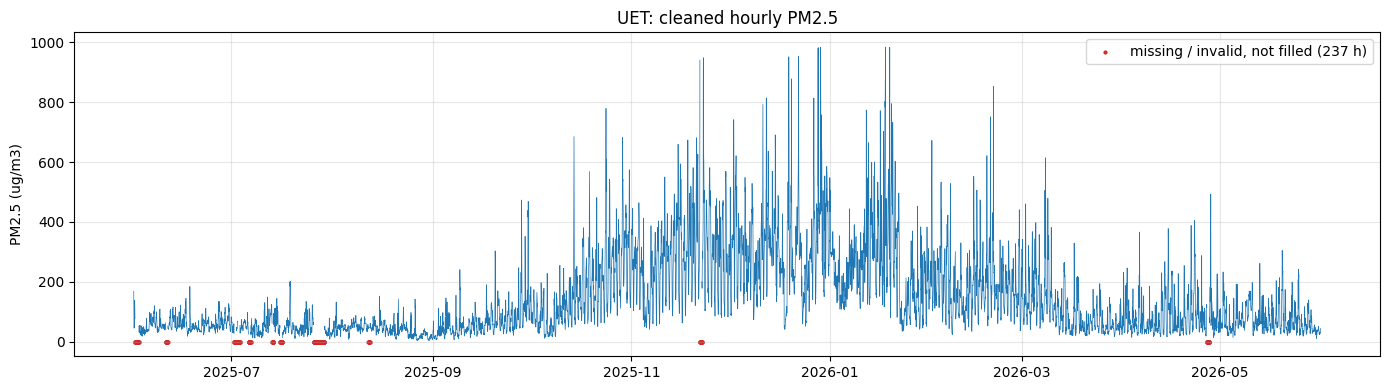

In [18]:
# ===== 4. Step 3/8: cleaning =====
banner("Step 3/8: cleaning")

clean_log = []
def log_step(step, n, detail=""):
    clean_log.append({"step": step, "count": int(n), "detail": detail})

rows = raw_rows.copy()
log_step("Rows read from the UET column/sheet (all workbooks)", len(rows), "")

# 1. Timestamps
_bad = rows["timestamp"].isna()
log_step("Rows dropped: no usable timestamp", _bad.sum(),
         "examples: " + ", ".join(map(str, rows.loc[_bad, "raw_time"].astype(str).unique()[:6])))
rows = rows.loc[~_bad].copy()
rows["hour"] = rows["timestamp"].dt.round("h").astype("datetime64[ns]")
log_step("Timestamps adjusted to the exact hour (float jitter / rounding)", (rows["timestamp"] != rows["hour"]).sum(), "")
log_step("Timestamps MORE than 1 minute away from the hour (rounded anyway)",
         ((rows["timestamp"] - rows["hour"]).abs() > pd.Timedelta(minutes=1)).sum(),
         "should be 0 for hourly data")
log_step("Timestamps stored as Excel serial numbers", (rows["ts_kind"] == "excel_serial").sum(),
         "converted from the 1899-12-30 epoch")

# 2. Values
log_step("Values stored as text but numeric (converted)", (rows["val_kind"] == "numeric_text").sum(), "")
log_step("Blank values", (rows["val_kind"] == "blank").sum(), "become missing")
log_step("Non-numeric / non-finite values", rows["val_kind"].isin(["non_numeric_text", "non_finite"]).sum(), "become missing")

# 3. Deduplicate
_g = rows.groupby("hour")["value"]
_n_per_hour = _g.size()
log_step("Hours that appear in more than one row (duplicates)", (_n_per_hour > 1).sum(), "")
log_step("... of which the duplicate rows DISAGREE (averaged)", (_g.nunique(dropna=True) > 1).sum(), "")
hourly_raw = _g.mean().sort_index()
log_step("Unique hourly timestamps after deduplication", len(hourly_raw),
         f"{hourly_raw.index.min()} to {hourly_raw.index.max()}")

# 4. Continuous hourly index
full_idx = pd.date_range(hourly_raw.index.min(), hourly_raw.index.max(), freq="h")
raw_hourly = hourly_raw.reindex(full_idx)
no_row = ~full_idx.isin(hourly_raw.index)
log_step("Hours in the continuous hourly index", len(full_idx), "")
log_step("Hours with NO row at all (absent from the workbooks)", no_row.sum(), "")
log_step("Hours present but value blank/non-numeric", (raw_hourly.isna() & ~no_row).sum(), "")

# 5. Invalid readings
nonpos = raw_hourly <= 0
_baseline = raw_hourly.where(~nonpos).rolling(SPIKE_WINDOW_H, center=True, min_periods=SPIKE_WINDOW_H // 2).median()
spike = (raw_hourly >= SPIKE_MIN) & (raw_hourly > SPIKE_RATIO * _baseline)
log_step("Invalid: non-positive readings (<= 0 ug/m3), set to missing", nonpos.sum(), "sensor dropouts")
log_step(f"Invalid: suspected sensor spikes (>= {SPIKE_MIN:.0f} and > {SPIKE_RATIO:g}x 14-day median), set to missing",
         spike.sum(), "")
valid = raw_hourly.where(~nonpos & ~spike)

status = pd.Series(np.where(nonpos, "invalid_nonpositive",
                   np.where(spike, "invalid_spike",
                   np.where(raw_hourly.isna(), "missing", "observed"))), index=full_idx)

# 6. Trim ends, then interpolate short internal gaps only
_first, _last = valid.first_valid_index(), valid.last_valid_index()
log_step("Leading/trailing hours trimmed (no valid reading yet / any more)",
         len(full_idx) - len(valid.loc[_first:_last]), f"series now {_first} to {_last}")
valid, status, raw_hourly = valid.loc[_first:_last], status.loc[_first:_last], raw_hourly.loc[_first:_last]

_isna = valid.isna()
_grp = (_isna != _isna.shift(fill_value=False)).cumsum()
_run_len = _isna.groupby(_grp).transform("sum")
fill_mask = _isna & (_run_len <= MAX_INTERP_GAP_H)
_interp = valid.interpolate(method="linear", limit_area="inside")
clean = valid.where(~fill_mask, _interp)
status = status.mask(fill_mask, "interpolated")

def runs_of(mask):
    mask = mask.astype(bool)
    if not mask.any():
        return pd.DataFrame({"start": pd.Series(dtype="datetime64[ns]"), "end": pd.Series(dtype="datetime64[ns]"), "hours": pd.Series(dtype=int)})
    grp = (mask != mask.shift(fill_value=False)).cumsum()
    idx = pd.Series(mask.index, index=mask.index)
    out = idx[mask].groupby(grp[mask]).agg(start="min", end="max", hours="count")
    return out.reset_index(drop=True)

gaps = runs_of(valid.isna())
gaps["interpolated"] = gaps["hours"] <= MAX_INTERP_GAP_H
log_step(f"Gaps found (runs of missing/invalid hours)", len(gaps), "")
log_step(f"Gaps interpolated (whole run <= {MAX_INTERP_GAP_H} h)", gaps["interpolated"].sum(),
         f"{int(fill_mask.sum())} hours filled")
log_step(f"Gaps LEFT missing (run > {MAX_INTERP_GAP_H} h; ARIMA treats them as missing observations)",
         (~gaps["interpolated"]).sum(), f"{int(gaps.loc[~gaps['interpolated'], 'hours'].sum())} hours")

cleaned = pd.DataFrame({"pm25_raw": raw_hourly, "pm25_clean": clean, "status": status})
cleaned.index.name = "timestamp"
series_obs = cleaned["pm25_clean"].asfreq("h")

print("CLEANING LOG")
cleaning_log = pd.DataFrame(clean_log)
display(cleaning_log)

print("\nHour-by-hour status of the final continuous series:")
_st = cleaned["status"].value_counts().rename("hours").to_frame()
_st["percent"] = (100 * _st["hours"] / len(cleaned)).round(2)
display(_st)

# Overview of the cleaned series
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(series_obs.index, series_obs.values, lw=0.5, color="tab:blue")
_bad_h = cleaned.index[cleaned["status"].isin(["missing", "invalid_nonpositive", "invalid_spike"])]
ax.scatter(_bad_h, np.zeros(len(_bad_h)), s=4, color="tab:red", label=f"missing / invalid, not filled ({len(_bad_h)} h)")
ax.set_title(f"{TARGET_STATION}: cleaned hourly PM2.5")
ax.set_ylabel("PM2.5 (ug/m3)")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Step 4/8: chronological split + stationarity diagnostics

In [19]:
# ===== 5. Step 4/8: chronological split + stationarity diagnostics =====
banner("Step 4/8: chronological split + stationarity diagnostics")

n = len(series_obs)
n_train = int(round(TRAIN_FRAC * n))
n_val = int(round(VAL_FRAC * n))
train_obs = series_obs.iloc[:n_train]
val_obs = series_obs.iloc[n_train:n_train + n_val]
test_obs = series_obs.iloc[n_train + n_val:]
cleaned["split"] = "train"
cleaned.loc[val_obs.index, "split"] = "validation"
cleaned.loc[test_obs.index, "split"] = "test"

split_table = pd.DataFrame({
    "start": [s.index[0] for s in (train_obs, val_obs, test_obs)],
    "end": [s.index[-1] for s in (train_obs, val_obs, test_obs)],
    "hours": [len(s) for s in (train_obs, val_obs, test_obs)],
    "valid_hours": [int(s.notna().sum()) for s in (train_obs, val_obs, test_obs)],
    "mean_ug_m3": [round(s.mean(), 1) for s in (train_obs, val_obs, test_obs)],
    "std_ug_m3": [round(s.std(), 1) for s in (train_obs, val_obs, test_obs)],
}, index=["train (70%)", "validation (15%)", "test (15%)"])
display(split_table)

def to_model(x):
    """Original ug/m3 -> modelling scale."""
    return np.log1p(x) if LOG_TRANSFORM else x

def from_model(x):
    """Modelling scale -> ug/m3 (never negative when the log transform is on)."""
    return np.clip(np.expm1(x), 0, None) if LOG_TRANSFORM else x

train_y = to_model(train_obs)

_tr = train_y.dropna()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    _adf_level = adfuller(_tr, autolag="AIC")
    _adf_diff = adfuller(_tr.diff().dropna(), autolag="AIC")
display(pd.DataFrame({
    "series (train, model scale)": ["level", "first difference"],
    "ADF statistic": [round(_adf_level[0], 2), round(_adf_diff[0], 2)],
    "p-value": [float(f"{_adf_level[1]:.3g}"), float(f"{_adf_diff[1]:.3g}")],
    "1% critical value": [round(_adf_level[4]["1%"], 2), round(_adf_diff[4]["1%"], 2)],
}))


[16:13:09 | +  1.0 min] Step 4/8: chronological split + stationarity diagnostics


,start,end,hours,valid_hours,mean_ug_m3,std_ug_m3
train (70%),2025-06-01 00:00:00,2026-02-11 11:00:00,6132,5912,158.8,148.5
validation (15%),2026-02-11 12:00:00,2026-04-07 05:00:00,1314,1314,127.0,95.6
test (15%),2026-04-07 06:00:00,2026-05-31 23:00:00,1314,1297,77.9,57.9


,"series (train, model scale)",ADF statistic,p-value,1% critical value
0,level,-3.35,0.0129,-3.43
1,first difference,-22.16,0.0000,-3.43


### Step 5/8: auto_arima + Fourier order selection on full dataset

In [ ]:
# ===== 6. Step 5/8: ARIMA + Fourier order selection by AIC on the TRAINING part only =====
banner("Step 5/8: ARIMA + Fourier order selection (AIC, training part only)")
# FIX: before, auto_arima was run on the FULL series, so the test hours helped choose the model.
# Now every candidate order is fitted on the first 70% only and the lowest AIC wins.

def make_fourier(index, period=FOURIER_PERIOD, n_harmonics=N_HARMONICS):
    """Deterministic Fourier terms from the hour-of-day."""
    hour = index.hour.astype(float)
    cols = {}
    for k in range(1, n_harmonics + 1):
        cols[f"sin_{k}"] = np.sin(2 * np.pi * k * hour / period)
        cols[f"cos_{k}"] = np.cos(2 * np.pi * k * hour / period)
    return pd.DataFrame(cols, index=index)

fourier_full = make_fourier(series_obs.index)

def regression_metrics(y_true, y_pred):
    """RMSE, MAE, MAPE and R2 using NumPy."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    m = np.isfinite(y_true) & np.isfinite(y_pred)
    yt, yp = y_true[m], y_pred[m]
    if yt.size == 0:
        return {"n": 0, "rmse": np.nan, "mae": np.nan, "mape_pct": np.nan, "r2": np.nan}
    err = yp - yt
    nz = yt != 0
    ss_tot = np.sum((yt - yt.mean()) ** 2)
    return {
        "n": int(yt.size),
        "rmse": float(np.sqrt(np.mean(err ** 2))),
        "mae": float(np.mean(np.abs(err))),
        "mape_pct": float(np.mean(np.abs(err[nz] / yt[nz])) * 100) if nz.any() else np.nan,
        "r2": float(1.0 - np.sum(err ** 2) / ss_tot) if ss_tot > 0 else np.nan,
    }

def fit_arima(y, order, exog=None):
    """Fit ARIMA with optional Fourier exog."""
    model = ARIMA(y, order=order, exog=exog,
                  enforce_stationarity=True, enforce_invertibility=True)
    return model.fit(method="statespace", method_kwargs={"maxiter": MAXITER})

def rolling_one_step_forecast(res, future_obs, future_exog, alpha=ALPHA):
    """Predict each hour from the real previous hours (parameters stay fixed)."""
    future_y = to_model(future_obs)
    frames = []
    current_res = res
    for i in range(len(future_y)):
        exog_i = future_exog.iloc[i:i+1]
        fc = current_res.get_forecast(steps=1, exog=exog_i)
        ci = fc.conf_int(alpha=alpha)
        actual_original = future_obs.iloc[i]
        frames.append({
            "timestamp": future_y.index[i],
            "observed": float(actual_original) if pd.notna(actual_original) else np.nan,
            "pred": float(from_model(float(fc.predicted_mean.iloc[0]))),
            "lo":   float(from_model(float(ci.iloc[0, 0]))),
            "hi":   float(from_model(float(ci.iloc[0, 1]))),
            "lead_hour": 1,
        })
        current_res = current_res.extend(future_y.iloc[i:i+1], exog=exog_i)
    return pd.DataFrame(frames).set_index("timestamp")

# ---- AIC grid on the training part (32 fits; can take several minutes) ----
P_RANGE, D_RANGE, Q_RANGE = range(0, 4), range(0, 2), range(0, 4)
train_exog = fourier_full.loc[train_obs.index]
print(f"Fitting {len(P_RANGE) * len(D_RANGE) * len(Q_RANGE)} candidate orders on {train_y.notna().sum():,} training hours ...")
_aic_rows = []
for p, d, q in itertools.product(P_RANGE, D_RANGE, Q_RANGE):
    _t = time.perf_counter()
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            _r = fit_arima(train_y, (p, d, q), train_exog)
        _aic = float(_r.aic)
        _conv = bool(_r.mle_retvals.get("converged", True)) if getattr(_r, "mle_retvals", None) else True
    except Exception as e:
        _aic, _conv = np.nan, False
    _aic_rows.append({"order": (p, d, q), "aic": _aic, "converged": _conv, "seconds": round(time.perf_counter() - _t, 1)})
    print(f"  ARIMA{(p, d, q)}  AIC={_aic:12,.1f}  converged={_conv}  ({_aic_rows[-1]['seconds']} s)", flush=True)

aic_table = pd.DataFrame(_aic_rows).sort_values("aic")
_ok = aic_table[aic_table["converged"] & np.isfinite(aic_table["aic"])]
if _ok.empty:
    raise RuntimeError("No candidate order converged on the training part.")
BEST_ORDER = tuple(int(v) for v in _ok.iloc[0]["order"])
BEST_AIC = float(_ok.iloc[0]["aic"])
MODEL_LABEL = f"ARIMA{BEST_ORDER}+Fourier({FOURIER_PERIOD},h={N_HARMONICS})"

print("\nTop 10 orders by AIC (training part only):")
display(aic_table.head(10))
print("\n" + "=" * 55)
print(f"  SELECTED MODEL (lowest AIC, train only): {MODEL_LABEL}")
print(f"  AIC (train): {BEST_AIC:,.2f}")
print("=" * 55)

### Step 6/8: Refit Selected Order & Score Test Set

In [ ]:
# ===== 7. Step 6/8: refit on train+validation with Fourier, score TEST =====
banner("Step 6/8: refit selected order on train+validation, score the TEST set")

dev_obs   = pd.concat([train_obs, val_obs])
dev_y     = to_model(dev_obs)
dev_exog  = fourier_full.loc[dev_obs.index]
test_exog = fourier_full.loc[test_obs.index]

def fit_with_fallback(y, order, exog, fallback_res, fallback_new_data, fallback_new_exog, label=""):
    """Refit; if it fails to converge, extend the previous (converged) fit and warn."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = fit_arima(y, order, exog)
    rv = getattr(res, "mle_retvals", None)
    converged = True if not rv else bool(rv.get("converged", False))
    if converged and np.all(np.isfinite(res.params)):
        return res, True
    print(f"  WARNING: refit '{label}' did not converge; falling back to previously validated parameters.")
    return fallback_res.extend(fallback_new_data, exog=fallback_new_exog), False

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    _res_train = fit_arima(train_y, BEST_ORDER, train_exog)

res_dev, dev_converged = fit_with_fallback(
    dev_y, BEST_ORDER, dev_exog,
    _res_train, to_model(val_obs), fourier_full.loc[val_obs.index], "train+validation"
)
print(f"{MODEL_LABEL} refit on train+validation ({len(dev_y):,} h): converged = {dev_converged}")
print(f"Rolling 1-hour-ahead prediction over {len(test_obs):,} test hours (about 1-3 minutes) ...")

test_fc = rolling_one_step_forecast(res_dev, test_obs, test_exog)

# FIX: every test prediction is 1 hour ahead, so the old "lead 1-24 / 25-72 / 73-168 h" rows were wrong.
test_overall = regression_metrics(test_fc["observed"], test_fc["pred"])
test_metrics = pd.DataFrame([{"order": MODEL_LABEL, "scope": "TEST, rolling 1 hour ahead", **test_overall}])
test_metrics = test_metrics.rename(columns={"n": "n_hours_scored"})

print("\nTEST METRICS (ug/m3)")
display(test_metrics.round(3))
print(f"\nAIC (training part): {BEST_AIC:,.2f}  |  Test RMSE: {test_overall['rmse']:.2f}")

In [ ]:
# ===== 8. Test evaluation — rolling one-step-ahead =====
test_overall = regression_metrics(test_fc["observed"], test_fc["pred"])
test_metrics_summary = pd.DataFrame([{
    "order": MODEL_LABEL,
    "scope": "TEST — rolling 1-hour-ahead",
    **test_overall
}]).rename(columns={"n": "n_hours_scored"})
print("\nTEST METRICS — rolling one-step-ahead")
display(test_metrics_summary.round(3))
print("\nTest forecast preview (first 12 hours):")
display(test_fc.head(12).round(2))

In [ ]:
# ===== 9. Baseline comparison: ARIMA+Fourier vs persistence (previous hour) =====
# Both use the real value of the previous hour, so this comparison is fair.
naive_pred = test_obs.shift(1)
naive_metrics = regression_metrics(test_obs, naive_pred)
baseline_comparison = pd.DataFrame([
    {"model": "Persistence (this hour = previous hour)", "RMSE": naive_metrics["rmse"], "MAE": naive_metrics["mae"],
     "MAPE (%)": naive_metrics["mape_pct"], "R2": naive_metrics["r2"], "n": naive_metrics["n"]},
    {"model": MODEL_LABEL, "RMSE": test_overall["rmse"], "MAE": test_overall["mae"],
     "MAPE (%)": test_overall["mape_pct"], "R2": test_overall["r2"], "n": test_overall["n"]},
])
print("\nARIMA+FOURIER VS PERSISTENCE (test hours)")
display(baseline_comparison.round(3))
_gain = naive_metrics["rmse"] - test_overall["rmse"]
print(f"RMSE gain of ARIMA over persistence: {_gain:+.2f} ug/m3 "
      "(close to 0 means ARIMA adds almost nothing beyond 'repeat the last hour').")

### step: 7/8 holdout graph

In [ ]:
# ===== 10. Step 7/8: holdout graph =====
banner("Step 7/8: holdout graph")
OUT_DIR.mkdir(parents=True, exist_ok=True)
_ymax = 1.1 * max(float(np.nanmax(test_fc["observed"])), float(np.nanpercentile(test_fc["hi"], 90)))
fig, ax = plt.subplots(figsize=(15, 5.5))
ax.fill_between(test_fc.index, test_fc["lo"], test_fc["hi"], color="tab:blue", alpha=0.13, label="95% interval")
ax.plot(test_fc.index, test_fc["observed"], color="black", lw=0.9, label="Observed")
ax.plot(test_fc.index, test_fc["pred"], color="tab:red", lw=1.4, label=f"{MODEL_LABEL} prediction")
for _t in test_fc.index[::HORIZON][1:]:
    ax.axvline(_t, color="grey", lw=0.6, ls=":")
ax.set_ylim(0, _ymax)
ax.set_title(f"{TARGET_STATION} holdout (test) period: observed vs {MODEL_LABEL}\n"
             f"RMSE {test_overall['rmse']:.1f} | MAE {test_overall['mae']:.1f} | "
             f"MAPE {test_overall['mape_pct']:.1f}% | R2 {test_overall['r2']:.3f}")
ax.set_ylabel("PM2.5 (ug/m3)")
ax.grid(alpha=0.3)
ax.legend(loc="upper right")
plt.tight_layout()
HOLDOUT_PNG = OUT_DIR / "holdout_test_forecast.png"
fig.savefig(HOLDOUT_PNG, dpi=150)
plt.show()
print("Saved:", HOLDOUT_PNG)

### Step 7/8 (b): training and test side by side
Shows the whole hourly series split into **train | validation | test**, separated by vertical lines (test shaded).
- Train and validation: the model's 1-hour-ahead values on hours it was **fitted on** (in-sample).
- Test: the 1-hour-ahead predictions from Step 6/8 on hours the model **never saw**.

Top panel = daily means (so a whole year is readable). Bottom panel = hourly zoom: the last 7 days before the test and the first 7 days of the test.
A table prints R2 / RMSE / bias for each part, for ARIMA and for "this hour = previous hour".

**Look for:** whether the error grows after the test line (a big jump = the model learned the training period but not what comes next).

In [ ]:
# ===== 10b. Step 7/8 (b): training vs test graph =====
banner("Step 7/8 (b): training vs test graph")

_fv = res_dev.fittedvalues
_fv = pd.Series(np.clip(np.asarray(from_model(np.asarray(_fv, float)), float), 0, None),
                index=_fv.index if isinstance(_fv.index, pd.DatetimeIndex) else dev_obs.index[-len(_fv):])
_fv = _fv.reindex(dev_obs.index)
_fv.iloc[:24] = np.nan                                  # first day: model still warming up

hourly_all = pd.DataFrame({"observed": series_obs})
hourly_all[MODEL_LABEL] = pd.concat([_fv, test_fc["pred"]]).reindex(series_obs.index)
hourly_all["Persistence (previous hour)"] = series_obs.shift(1)

_parts = {"train (fitted)": train_obs.index, "validation (fitted)": val_obs.index, "test (never seen)": test_obs.index}
_rows = []
for _m in [MODEL_LABEL, "Persistence (previous hour)"]:
    for _p, _ix in _parts.items():
        _s = regression_metrics(hourly_all.loc[_ix, "observed"], hourly_all.loc[_ix, _m])
        _o, _q = hourly_all.loc[_ix, "observed"], hourly_all.loc[_ix, _m]
        _ok = _o.notna() & _q.notna()
        _rows.append({"model": _m, "part": _p, "R2": _s["r2"], "RMSE": _s["rmse"],
                      "bias": float((_q[_ok] - _o[_ok]).mean()), "hours": _s["n"]})
train_test_table = pd.DataFrame(_rows)
display(train_test_table.round(3))

_val_start, _test_start = val_obs.index[0], test_obs.index[0]
fig, axes = plt.subplots(2, 1, figsize=(16, 9))

# top: daily means over the whole period
_d = hourly_all.resample("D").mean()
ax = axes[0]
ax.plot(_d.index, _d["observed"], color="black", lw=1.4, label="Observed (daily mean)")
ax.plot(_d.index, _d[MODEL_LABEL], color="tab:red", lw=1.1, label=f"{MODEL_LABEL} (daily mean of 1-h-ahead values)")
ax.axvspan(_test_start, _d.index[-1] + pd.Timedelta(days=1), color="tab:orange", alpha=0.10)
for _t, _lab in [(_val_start, "train | validation"), (_test_start, "validation | TEST")]:
    ax.axvline(_t, color="grey", lw=1.5, ls="--")
    ax.text(_t, ax.get_ylim()[1] * 0.95, " " + _lab, va="top", fontsize=9)
_tr = train_test_table.set_index(["model", "part"])
ax.set_title(f"{TARGET_STATION}: whole series — train R2 {_tr.loc[(MODEL_LABEL, 'train (fitted)'), 'R2']:.2f}, "
             f"validation R2 {_tr.loc[(MODEL_LABEL, 'validation (fitted)'), 'R2']:.2f}, "
             f"test R2 {_tr.loc[(MODEL_LABEL, 'test (never seen)'), 'R2']:.2f} (hourly scores)")
ax.set_ylabel("PM2.5 (ug/m3)"); ax.grid(alpha=0.3); ax.legend(loc="upper right")

# bottom: hourly zoom around the test start
_z = hourly_all.loc[_test_start - pd.Timedelta(days=7): _test_start + pd.Timedelta(days=7)]
ax = axes[1]
ax.plot(_z.index, _z["observed"], color="black", lw=1.2, label="Observed (hourly)")
ax.plot(_z.index, _z[MODEL_LABEL], color="tab:red", lw=1.0, label=f"{MODEL_LABEL} (1 h ahead)")
ax.plot(_z.index, _z["Persistence (previous hour)"], color="tab:blue", lw=0.8, ls=":", label="Persistence (previous hour)")
ax.axvspan(_test_start, _z.index[-1], color="tab:orange", alpha=0.10)
ax.axvline(_test_start, color="grey", lw=1.5, ls="--")
ax.text(_test_start, ax.get_ylim()[1] * 0.95, "  TEST starts", va="top", fontsize=9)
ax.set_title("Zoom: last 7 days before the test (fitted) and first 7 days of the test (never seen)")
ax.set_ylabel("PM2.5 (ug/m3)"); ax.grid(alpha=0.3); ax.legend(loc="upper right")

plt.tight_layout()
TRAIN_TEST_PNG = OUT_DIR / "holdout_train_test.png"
fig.savefig(TRAIN_TEST_PNG, dpi=150)
plt.show()
train_test_table.to_csv(OUT_DIR / "train_validation_test_scores.csv", index=False)
print("Saved:", TRAIN_TEST_PNG, "and train_validation_test_scores.csv")

In [ ]:
# ===== 11. Step 7/8: ETS 24-hour forecast on recent data =====
banner("Step 7/8: ETS (Exponential Smoothing) 24-hour forecast")

from statsmodels.tsa.holtwinters import ExponentialSmoothing

FORECAST_HORIZON = 24
ETS_WINDOW_DAYS  = 30   # 30 days — stays within current season, correct level

# ── 1. Recent clean window ────────────────────────────────────────────────────
# Use last 30 days, interpolate tiny gaps, enforce hourly freq.
# 30 days = 720 hours, enough to learn 24-h daily seasonality (30 full cycles).
recent_raw = series_obs.iloc[-ETS_WINDOW_DAYS * 24:]
recent_obs = recent_raw.interpolate(method='linear').ffill().bfill().asfreq('h')
last_obs_time = series_obs.dropna().index[-1]
last_obs_val  = float(series_obs.dropna().iloc[-1])
print(f'ETS window : {recent_obs.index[0]:%Y-%m-%d} to {recent_obs.index[-1]:%Y-%m-%d} ({len(recent_obs):,} h)')
print(f'Last observed : {last_obs_val:.2f} ug/m3  at  {last_obs_time}')

# ── 2. Fit ETS(A,Ad,A) ────────────────────────────────────────────────────────
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ets_model = ExponentialSmoothing(
        recent_obs,
        trend="add",
        seasonal="add",
        seasonal_periods=24,
        damped_trend=True,
        initialization_method="estimated",
        freq='h',
    )
    ets_fit = ets_model.fit(optimized=True, remove_bias=True)

print(f'  alpha={ets_fit.params["smoothing_level"]:.4f}  '
      f'beta={ets_fit.params["smoothing_trend"]:.4f}  '
      f'gamma={ets_fit.params["smoothing_seasonal"]:.4f}  '
      f'phi={ets_fit.params["damping_trend"]:.4f}')
print(f'  AIC: {ets_fit.aic:.2f}')

# ── 3. Forecast using simulate(anchor='end') ──────────────────────────────────
# simulate(anchor='end') starts from the FINAL fitted state of the model
# (i.e. the smoothed level/trend/seasonal at the last observed hour).
# This guarantees the forecast starts at the current level, not the mean.
# Returns a DataFrame of shape (nsimulations, FORECAST_HORIZON);
# we take the mean across simulations as the point forecast.
np.random.seed(42)
_sims = ets_fit.simulate(
    anchor='end',
    nsimulations=FORECAST_HORIZON,
    repetitions=200,
    random_errors='bootstrap',
)
# _sims shape: (FORECAST_HORIZON, 200)
_fc_vals   = np.clip(np.asarray(_sims).mean(axis=1), 0, None)
_fc_lo     = np.clip(np.percentile(np.asarray(_sims), 2.5,  axis=1), 0, None)
_fc_hi     = np.clip(np.percentile(np.asarray(_sims), 97.5, axis=1), 0, None)

fut_index = pd.date_range(last_obs_time + pd.Timedelta(hours=1),
                          periods=FORECAST_HORIZON, freq='h')

future_fc = pd.DataFrame({
    "horizon_h":      np.arange(1, FORECAST_HORIZON + 1),
    "forecast_ug_m3": _fc_vals,
    "lower_95":       _fc_lo,
    "upper_95":       _fc_hi,
}, index=fut_index)
future_fc.index.name = "timestamp"

# ── 4. In-sample metrics ──────────────────────────────────────────────────────
in_sample_pred    = np.clip(np.asarray(ets_fit.fittedvalues), 0, None)
ets_train_metrics = regression_metrics(recent_obs.values, in_sample_pred)
print(f'\nETS in-sample metrics (last {ETS_WINDOW_DAYS} days):')
print(f'  RMSE : {ets_train_metrics["rmse"]:.2f} ug/m3')
print(f'  MAE  : {ets_train_metrics["mae"]:.2f} ug/m3')
print(f'  R2   : {ets_train_metrics["r2"]:.4f}')

# ── 5. Verification ───────────────────────────────────────────────────────────
fc_std   = future_fc['forecast_ug_m3'].std()
fc_min   = future_fc['forecast_ug_m3'].min()
fc_max   = future_fc['forecast_ug_m3'].max()
first_fc = float(future_fc['forecast_ug_m3'].iloc[0])
print(f'\n[VERIFICATION]')
print(f'  Last observed       : {last_obs_val:.2f} ug/m3')
print(f'  First forecast (h+1): {first_fc:.2f} ug/m3  (should be close)')
print(f'  Forecast range      : {fc_min:.2f} to {fc_max:.2f} ug/m3')
print('\nForecast (next 24 hours):')
display(future_fc.round(2))

# ── 6. Plot ───────────────────────────────────────────────────────────────────
hist = series_obs.iloc[-3 * 24:].dropna()
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(hist.index, hist.values, color='black', lw=1.2,
        label='Observed (last 3 days)')
ax.fill_between(future_fc.index, future_fc['lower_95'], future_fc['upper_95'],
                color='tab:blue', alpha=0.25, label='95% CI (bootstrap)')
ax.plot(future_fc.index, future_fc['forecast_ug_m3'],
        color='tab:red', lw=2.0, label='ETS(A,Ad,A)[24] 24h forecast')
ax.axvline(last_obs_time, color='grey', ls='--', lw=1, label='Forecast origin')
_ymax = 1.2 * max(float(np.nanmax(hist.values)),
                  float(future_fc['upper_95'].max()))
ax.set_ylim(0, _ymax)
ax.set_title(
    f'{TARGET_STATION}: 24-hour PM2.5 Forecast (ETS)  |  '
    f'Origin: {last_obs_time:%Y-%m-%d %H:%M}'
)
ax.set_ylabel('PM2.5 (ug/m3)')
ax.grid(alpha=0.3)
ax.legend(loc='upper left')
plt.tight_layout()
FORECAST_PNG = OUT_DIR / 'forecast_24h_ets.png'
fig.savefig(FORECAST_PNG, dpi=150)
plt.show()
print('Saved:', FORECAST_PNG)

### Step 8/8: saving outputs & final summary

In [ ]:
# ===== 12. Step 8/8: saving outputs & final summary =====
banner("Step 8/8: saving outputs")
FILES = {
    "cleaned data":     OUT_DIR / "cleaned_uet_hourly.csv",
    "test forecasts":   OUT_DIR / "test_forecasts.csv",
    "test metrics":     OUT_DIR / "test_metrics.csv",
    "future forecast":  OUT_DIR / "future_forecast_24h_ets.csv",
    "cleaning log":     OUT_DIR / "cleaning_log.csv",
}
cleaned.to_csv(FILES["cleaned data"], float_format="%.4f")
test_fc.to_csv(FILES["test forecasts"], index_label="timestamp", float_format="%.4f")
_tm = test_metrics.copy()
_tm["aic_selected_order_train"] = BEST_AIC
_tm.to_csv(FILES["test metrics"], index=False, float_format="%.5f")
future_fc.to_csv(FILES["future forecast"], float_format="%.4f")
cleaning_log.to_csv(FILES["cleaning log"], index=False)
_listing = [(k, p.name) for k, p in FILES.items()] + [
    ("holdout graph", HOLDOUT_PNG.name), ("forecast graph", FORECAST_PNG.name)]
_out = pd.DataFrame({
    "output": [k for k, _ in _listing],
    "file": [n for _, n in _listing],
    "size_kb": [round((OUT_DIR / n).stat().st_size / 1024, 1) for _, n in _listing],
})
display(_out)
assert (_out["size_kb"] > 0).all()
banner("DONE: all steps completed successfully")
print(f'Selected model (lowest AIC)     : {MODEL_LABEL}  (chosen on training part only)')
print(f'AIC (training part)             : {BEST_AIC:.2f}')
print(f'Test RMSE / MAE / R2            : {test_overall["rmse"]:.2f} / {test_overall["mae"]:.2f} / {test_overall["r2"]:.3f}')
print(f'Forecast range                  : {future_fc.index[0]}  ->  {future_fc.index[-1]}')
print(f'ETS in-sample RMSE              : {ets_train_metrics["rmse"]:.2f} ug/m3')
print(f'Forecast variation (std dev)    : {fc_std:.2f} ug/m3')
print(f'Total run time                  : {(time.perf_counter() - _T0) / 60:.1f} min')

---
# Part B — daily UET PM2.5 with the new satellite / reanalysis data

What is actually in `data/raw/` (checked from the file names):

| folder | product | files | dates in file names |
|---|---|---|---|
| `merra_2/…` | MERRA-2 `tavg1_2d_aer_Nx` (aerosol, hourly, global grid) | 180 | 2025-09-01 → 2026-02-27 |
| `merra_2/…` | MERRA-2 `tavg1_2d_slv_Nx` (weather, hourly, global grid) | 180 | 2025-09-01 → 2026-02-27 |
| `modis_2026` | MODIS MCD19A2 AOD 1 km, tile h24v05 | 59 | 2026-01-01 → 2026-02-28 |
| `tropomi_2026` | TROPOMI `L2__AER_AI` (UV aerosol index, **not** NO2/SO2) | 202 | 2025-09-01 → 2026-02-27 |
| `pm25` | 3 Excel workbooks + older CSV tables (incl. `matched_training_dataset.csv`) | 8 | — |

**There is no ERA5 folder and no aethalometer folder in `data/raw/`.** The satellite data only cover Sep 2025 – Feb 2026
(MODIS only Jan–Feb 2026), while PM2.5 covers Jun 2025 – May 2026.

So Part B runs two separate experiments (their scores must **not** be compared with each other — different days):
- **Experiment 1** — new raw data: MERRA-2 (+ TROPOMI aerosol index, + MODIS where possible), Sep 2025 – Feb 2026.
- **Experiment 2** — the older full-year table `raw/pm25/matched_training_dataset.csv` (ERA5, MODIS, TROPOMI NO2/SO2, CAMS), Jun 2025 – May 2026.
  Where this table came from is not documented in `raw/`, so treat it with care.

Every big file is read **one at a time**, only the pixel(s) at UET are read, and each file's result is saved in
`data/interim/uet_point/…`. If you stop the notebook, re-running skips files already done.

### B1 — Settings and file lists
**Please confirm** the UET location `31.58 N, 74.36 E` (used to pick the nearest pixel).
**Look for:** 180 + 180 MERRA-2 files, 59 MODIS files, 202 TROPOMI files.

In [ ]:
# ===== B1. Settings and file lists =====
import netCDF4

UET_LAT, UET_LON = 31.58, 74.36            # UET station — please confirm
PKT_OFFSET = pd.Timedelta(hours=5)          # Pakistan time = UTC + 5
MIN_HOURS_PER_DAY = 18                      # a daily mean needs at least 18 hours
TRAIN_FRAC_DAILY = 0.70                     # Part B split: first 70% of days train, last 30% test
POINT_CACHE = INTERIM / "uet_point"         # one small CSV per raw file (restartable)
DAILY_OUT = PROCESSED / "shi_daily"
for _d in (POINT_CACHE, DAILY_OUT):
    _d.mkdir(parents=True, exist_ok=True)

MERRA_AER_FILES   = sorted(RAW.glob("merra_2/**/*tavg1_2d_aer_Nx*.nc4"))
MERRA_SLV_FILES   = sorted(RAW.glob("merra_2/**/*tavg1_2d_slv_Nx*.nc4"))
MODIS_FILES       = sorted(RAW.glob("**/MCD19A2.A*.hdf"))
TROPOMI_AAI_FILES = sorted(RAW.glob("**/S5P_*L2__AER_AI_*.nc"))
OLD_MATCHED_TABLE = RAW / "pm25" / "matched_training_dataset.csv"

for _name, _files in [("MERRA-2 aer", MERRA_AER_FILES), ("MERRA-2 slv", MERRA_SLV_FILES),
                      ("MODIS", MODIS_FILES), ("TROPOMI AAI", TROPOMI_AAI_FILES)]:
    _gb = sum(f.stat().st_size for f in _files) / 1e9
    print(f"{_name:12s}: {len(_files):4d} files, {_gb:6.2f} GB"
          + (f"   {_files[0].name}  ...  {_files[-1].name}" if _files else "   NONE FOUND"))
print("Old matched table:", OLD_MATCHED_TABLE.name, "found" if OLD_MATCHED_TABLE.exists() else "NOT FOUND")

### B2 — Daily UET PM2.5 (target)
From the cleaned hourly series of Part A: only hours with status `observed` are used (no interpolated hours,
readings ≤ 0 and spikes already removed). A day is kept only if it has at least 18 such hours.
The Excel times are taken as Pakistan local time.

Note: the candidate sensor-fault days 2025-06-01, 2025-06-02, 2025-07-03 are **not** blanked here; their hours are printed so you can decide.

**Look for:** number of valid days (about 330–360) and the printed hours of the three candidate days.

In [ ]:
# ===== B2. Daily UET PM2.5 =====
_obs = cleaned["pm25_clean"].where(cleaned["status"] == "observed")
_g = _obs.groupby(_obs.index.normalize())
uet_daily = pd.DataFrame({"pm25": _g.mean(), "valid_hours": _g.count()})
uet_daily.loc[uet_daily["valid_hours"] < MIN_HOURS_PER_DAY, "pm25"] = np.nan
uet_daily = uet_daily.asfreq("D")
uet_daily.index.name = "date"

print(f"Days in calendar: {len(uet_daily)}  |  days with a valid daily mean: {uet_daily['pm25'].notna().sum()}"
      f"  |  dropped (< {MIN_HOURS_PER_DAY} h): {(uet_daily['valid_hours'] < MIN_HOURS_PER_DAY).sum()}")
print(uet_daily["pm25"].describe().round(1).to_string())

for _day in ["2025-06-01", "2025-06-02", "2025-07-03"]:
    try:
        _h = cleaned.loc[_day, "pm25_raw"]
        print(f"\nCandidate sensor-fault day {_day}: daily mean = {uet_daily.loc[pd.Timestamp(_day), 'pm25']:.1f}, hourly raw values:")
        print(", ".join(f"{t:%H}h={v:.0f}" for t, v in _h.items()))
    except KeyError:
        print(f"\nCandidate sensor-fault day {_day}: not in the cleaned series (trimmed or absent)")

uet_daily.to_csv(DAILY_OUT / "uet_pm25_daily.csv")
print("\nSaved:", DAILY_OUT / "uet_pm25_daily.csv")

### B3 — MERRA-2 at the UET pixel (about 29 GB, 360 files)
The files are **global** (361 × 576 grid) even though their names say "subsetted", so for each file only the nearest
pixel to UET is read (24 hourly values per variable). Times are UTC (xx:30) and are shifted to Pakistan time (+5 h)
before the daily mean, so a Pakistan day uses the end of the previous UTC file.

Units: surface masses kg m⁻³ → µg m⁻³ (× 1e9), T2M / T2MDEW K → °C, PS Pa → hPa,
PBL depth = (PS − PBLTOP) in hPa, wind speed from U10M and V10M, RH from T2M and T2MDEW.
`m2_pm25_proxy_ugm3` = DUST + SEASALT + BC + 1.4·OC + 1.375·SO4 (uses **total** dust and sea salt, because the
2.5 µm fractions are not in these files, so it is only an approximation).

First run: roughly 10–30 minutes. **Look for:** the nearest pixel (lat 31.5, lon 74.375), 180 days, few missing days.

In [ ]:
# ===== B3. MERRA-2 point extraction (restartable) =====
AER_VARS = ["BCSMASS", "OCSMASS", "SO4SMASS", "DUSMASS", "SSSMASS", "TOTEXTTAU", "BCEXTTAU", "TOTSCATAU", "BCCMASS"]
SLV_VARS = ["T2M", "T2MDEW", "PS", "PBLTOP", "U10M", "V10M", "QV2M", "TQV"]

def merra_point_hourly(files, wanted, tag):
    """Read the UET pixel from each file, save one CSV per file, return all hours (UTC)."""
    cache = POINT_CACHE / f"merra2_{tag}"
    cache.mkdir(exist_ok=True)
    shown = False
    for i, f in enumerate(files, 1):
        out = cache / (f.stem + ".csv")
        if out.exists():
            continue
        print(f"  [{tag} {i}/{len(files)}] {f.name}  ({f.stat().st_size / 1e6:,.0f} MB)", flush=True)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            with netCDF4.Dataset(f) as nc:
                lat, lon = np.asarray(nc["lat"][:], float), np.asarray(nc["lon"][:], float)
                iy, ix = int(np.abs(lat - UET_LAT).argmin()), int(np.abs(lon - UET_LON).argmin())
                if not shown:
                    print(f"     nearest MERRA-2 pixel centre: lat {lat[iy]}, lon {lon[ix]}")
                    shown = True
                t = netCDF4.num2date(nc["time"][:], nc["time"].units,
                                     only_use_cftime_datetimes=False, only_use_python_datetimes=True)
                df = pd.DataFrame({"time_utc": pd.to_datetime(list(t))})
                for v in wanted:
                    if v in nc.variables:
                        df[v] = np.ma.filled(np.ma.asarray(nc[v][:, iy, ix]).astype(float), np.nan)
                    else:
                        df[v] = np.nan
        df.to_csv(out, index=False)
    parts = [pd.read_csv(cache / (f.stem + ".csv"), parse_dates=["time_utc"]) for f in files]
    allh = pd.concat(parts, ignore_index=True).sort_values("time_utc")
    dup = allh["time_utc"].duplicated().sum()
    print(f"  {tag}: {len(allh):,} hourly rows, {dup} repeated hours (dropped), "
          f"{allh['time_utc'].min()} to {allh['time_utc'].max()} UTC")
    return allh.drop_duplicates("time_utc")

with netCDF4.Dataset(MERRA_AER_FILES[0]) as _nc:
    print("AER variables in file:", [v for v in _nc.variables if v not in ("lat", "lon", "time")])
with netCDF4.Dataset(MERRA_SLV_FILES[0]) as _nc:
    print("SLV variables in file:", [v for v in _nc.variables if v not in ("lat", "lon", "time")])

aer_h = merra_point_hourly(MERRA_AER_FILES, AER_VARS, "aer")
slv_h = merra_point_hourly(MERRA_SLV_FILES, SLV_VARS, "slv")

def merra_daily(hourly, builders, min_hours=MIN_HOURS_PER_DAY):
    h = pd.DataFrame({"time_pkt": hourly["time_utc"] + PKT_OFFSET})
    for name, fn in builders.items():
        h[name] = fn(hourly).to_numpy()
    h["date"] = h["time_pkt"].dt.normalize()
    cols = list(builders)
    g = h.groupby("date")
    daily = g[cols].mean()
    hours = g[cols[0]].count()
    daily.loc[hours < min_hours, cols] = np.nan
    return daily, hours

KG_TO_UG = 1e9
_aer_builders = {
    "m2_bc_ugm3":   lambda d: d["BCSMASS"] * KG_TO_UG,
    "m2_oc_ugm3":   lambda d: d["OCSMASS"] * KG_TO_UG,
    "m2_so4_ugm3":  lambda d: d["SO4SMASS"] * KG_TO_UG,
    "m2_dust_ugm3": lambda d: d["DUSMASS"] * KG_TO_UG,
    "m2_salt_ugm3": lambda d: d["SSSMASS"] * KG_TO_UG,
    "m2_pm25_proxy_ugm3": lambda d: (d["DUSMASS"] + d["SSSMASS"] + d["BCSMASS"]
                                     + 1.4 * d["OCSMASS"] + 1.375 * d["SO4SMASS"]) * KG_TO_UG,
    "m2_aod":        lambda d: d["TOTEXTTAU"],
    "m2_bc_aod":     lambda d: d["BCEXTTAU"],
    "m2_scat_aod":   lambda d: d["TOTSCATAU"],
    "m2_bc_column_mgm2": lambda d: d["BCCMASS"] * 1e6,
}
def _rh(t_k, td_k):
    t, td = t_k - 273.15, td_k - 273.15
    return 100 * np.exp(17.625 * td / (243.04 + td)) / np.exp(17.625 * t / (243.04 + t))
_slv_builders = {
    "m2_t2m_c":         lambda d: d["T2M"] - 273.15,
    "m2_td2m_c":        lambda d: d["T2MDEW"] - 273.15,
    "m2_rh":            lambda d: _rh(d["T2M"], d["T2MDEW"]),
    "m2_ps_hpa":        lambda d: d["PS"] / 100,
    "m2_pbl_depth_hpa": lambda d: (d["PS"] - d["PBLTOP"]) / 100,
    "m2_u10":           lambda d: d["U10M"],
    "m2_v10":           lambda d: d["V10M"],
    "m2_wind_speed":    lambda d: np.hypot(d["U10M"], d["V10M"]),
    "m2_qv2m_gkg":      lambda d: d["QV2M"] * 1000,
    "m2_tqv":           lambda d: d["TQV"],
}
aer_daily, aer_hours = merra_daily(aer_h, _aer_builders)
slv_daily, slv_hours = merra_daily(slv_h, _slv_builders)
merra2_uet_daily = aer_daily.join(slv_daily, how="outer")
merra2_uet_daily["m2_aer_hours"] = aer_hours
merra2_uet_daily["m2_slv_hours"] = slv_hours
merra2_uet_daily.index.name = "date"

_valid = merra2_uet_daily.dropna(subset=["m2_pm25_proxy_ugm3", "m2_t2m_c"])
print(f"\nMERRA-2 daily (Pakistan days): {len(merra2_uet_daily)} days, {len(_valid)} complete "
      f"({_valid.index.min().date()} to {_valid.index.max().date()})")
print("Days dropped for < 18 hours:", merra2_uet_daily.index[merra2_uet_daily['m2_pm25_proxy_ugm3'].isna()].strftime('%Y-%m-%d').tolist())
display(merra2_uet_daily.describe().T.round(2))
merra2_uet_daily.to_csv(INTERIM / "merra2_uet_daily.csv")
print("Saved:", INTERIM / "merra2_uet_daily.csv")

### B4 — MODIS MCD19A2 AOD at UET (59 files, about 0.5 GB)
The files are on the MODIS sinusoidal grid (tile h24v05, 1 km). The UET pixel row/column is computed from the
projection, and a 3 × 3 window (about 3 × 3 km) around it is read for every satellite pass in the file.
`modis_aod055_qa` keeps only pixels with cloud mask = clear and QA = best; `modis_aod055_all` keeps every valid value.
`modis_n_qa` = how many good pixels that day (0 = cloud gap).

**Look for:** the pixel row/column (should be inside 0–1199), number of days with at least one good pixel.

In [ ]:
# ===== B4. MODIS point extraction (restartable) =====
R_SIN = 6371007.181                 # MODIS sinusoidal sphere radius (m)
TILE_M = 1111950.5197665            # tile width (m)
NPIX = 1200                         # 1 km grid: 1200 x 1200 per tile
PIX_M = TILE_M / NPIX

def modis_rowcol(lat, lon, h, v):
    x = R_SIN * np.radians(lon) * np.cos(np.radians(lat))
    y = R_SIN * np.radians(lat)
    ul_x = -20015109.354 + h * TILE_M
    ul_y = 10007554.677 - v * TILE_M
    return int((ul_y - y) // PIX_M), int((x - ul_x) // PIX_M)

_cache = POINT_CACHE / "modis"
_cache.mkdir(exist_ok=True)
_shown = False
for i, f in enumerate(MODIS_FILES, 1):
    out = _cache / (f.stem + ".csv")
    if out.exists():
        continue
    m = re.search(r"\.A(\d{4})(\d{3})\.h(\d{2})v(\d{2})\.", f.name)
    day = pd.Timestamp(int(m[1]), 1, 1) + pd.Timedelta(days=int(m[2]) - 1)
    r, c = modis_rowcol(UET_LAT, UET_LON, int(m[3]), int(m[4]))
    if not _shown:
        print(f"UET pixel in tile h{m[3]}v{m[4]}: row {r}, column {c}")
        _shown = True
    print(f"  [modis {i}/{len(MODIS_FILES)}] {f.name}  ({f.stat().st_size / 1e6:,.1f} MB)", flush=True)
    row = {"date": day, "file": f.name, "n_orbits": 0, "modis_n_all": 0, "modis_n_qa": 0,
           "modis_aod055_all": np.nan, "modis_aod055_qa": np.nan}
    if 1 <= r < NPIX - 1 and 1 <= c < NPIX - 1:
        with netCDF4.Dataset(f) as nc:
            aod = np.ma.filled(np.ma.asarray(nc["Optical_Depth_055"][:, r-1:r+2, c-1:c+2]).astype(float), np.nan)
            qv = nc["AOD_QA"]
            qv.set_auto_maskandscale(False)
            qa = np.asarray(qv[:, r-1:r+2, c-1:c+2]).astype(np.uint16)
        clear = (qa & 0b111) == 1                 # bits 0-2: cloud mask, 1 = clear
        best = ((qa >> 8) & 0b1111) == 0           # bits 8-11: QA, 0 = best
        good = np.isfinite(aod) & clear & best
        row.update(n_orbits=int(aod.shape[0]),
                   modis_n_all=int(np.isfinite(aod).sum()), modis_n_qa=int(good.sum()),
                   modis_aod055_all=float(np.nanmean(aod)) if np.isfinite(aod).any() else np.nan,
                   modis_aod055_qa=float(aod[good].mean()) if good.any() else np.nan)
    else:
        print("     UET is outside this tile — skipped")
    pd.DataFrame([row]).to_csv(out, index=False)

_mod = pd.concat([pd.read_csv(_cache / (f.stem + ".csv"), parse_dates=["date"]) for f in MODIS_FILES], ignore_index=True)
_mod["sum_qa"] = _mod["modis_aod055_qa"].fillna(0) * _mod["modis_n_qa"]      # helper for weighted mean only
_mod["sum_all"] = _mod["modis_aod055_all"].fillna(0) * _mod["modis_n_all"]
_g = _mod.groupby("date")
modis_uet_daily = pd.DataFrame({"modis_n_qa": _g["modis_n_qa"].sum(), "modis_n_all": _g["modis_n_all"].sum()})
modis_uet_daily["modis_aod055_qa"] = (_g["sum_qa"].sum() / modis_uet_daily["modis_n_qa"]).where(modis_uet_daily["modis_n_qa"] > 0)
modis_uet_daily["modis_aod055_all"] = (_g["sum_all"].sum() / modis_uet_daily["modis_n_all"]).where(modis_uet_daily["modis_n_all"] > 0)
modis_uet_daily.index.name = "date"
print(f"\nMODIS: {len(modis_uet_daily)} days, {(modis_uet_daily['modis_n_qa'] > 0).sum()} with a good (clear, best-QA) pixel, "
      f"{(modis_uet_daily['modis_n_all'] > 0).sum()} with any valid pixel")
display(modis_uet_daily.describe().T.round(3))
modis_uet_daily.to_csv(INTERIM / "modis_uet_daily.csv")
print("Saved:", INTERIM / "modis_uet_daily.csv")

### B5 — TROPOMI aerosol index at UET (202 files, about 48 GB)
Each file is one full orbit. Only `latitude` / `longitude` are read in full; then only the scan lines near UET are read
for `aerosol_index_354_388` and `qa_value`. Pixels within ±0.1° (about 10 km) of UET with `qa_value ≥ 0.8` are averaged.
The date is the Pakistan date of the overpass (around 13:00 local time).

First run: roughly 10–40 minutes. **Look for:** most days with `tropomi_n_good > 0`; days with 0 are cloud gaps or orbits that missed Lahore.

In [ ]:
# ===== B5. TROPOMI AER_AI point extraction (restartable) =====
TROPOMI_BOX_DEG = 0.10
TROPOMI_QA_MIN = 0.8

_cache = POINT_CACHE / "tropomi_aai"
_cache.mkdir(exist_ok=True)
_dlon = TROPOMI_BOX_DEG / np.cos(np.radians(UET_LAT))
for i, f in enumerate(TROPOMI_AAI_FILES, 1):
    out = _cache / (f.stem + ".csv")
    if out.exists():
        continue
    print(f"  [tropomi {i}/{len(TROPOMI_AAI_FILES)}] {f.name[:70]}  ({f.stat().st_size / 1e6:,.0f} MB)", flush=True)
    start = pd.to_datetime(re.search(r"_(\d{8}T\d{6})_\d{8}T\d{6}_", f.name)[1], format="%Y%m%dT%H%M%S")
    row = {"file": f.name, "time_utc": start, "n_in_box": 0, "tropomi_n_good": 0, "tropomi_aai": np.nan}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        with netCDF4.Dataset(f) as nc:
            p = nc["PRODUCT"]
            lat = np.ma.filled(np.ma.asarray(p["latitude"][0]).astype(float), np.nan)
            lon = np.ma.filled(np.ma.asarray(p["longitude"][0]).astype(float), np.nan)
            near = (np.abs(lat - UET_LAT) <= TROPOMI_BOX_DEG) & (np.abs(lon - UET_LON) <= _dlon)
            if near.any():
                rows = np.where(near.any(axis=1))[0]
                s0, s1 = int(rows.min()), int(rows.max()) + 1
                aai = np.ma.filled(np.ma.asarray(p["aerosol_index_354_388"][0, s0:s1, :]).astype(float), np.nan)
                qa = np.ma.filled(np.ma.asarray(p["qa_value"][0, s0:s1, :]).astype(float), np.nan)
                if np.nanmax(qa) > 1.5:          # not auto-scaled -> 0..100
                    qa = qa / 100.0
                try:
                    dtv = p["delta_time"]
                    tmid = pd.Timestamp(netCDF4.num2date(float(dtv[0, (s0 + s1) // 2]), dtv.units,
                                        only_use_cftime_datetimes=False, only_use_python_datetimes=True))
                except Exception:
                    tmid = start                      # fall back to the orbit start time
                sub = near[s0:s1]
                good = sub & np.isfinite(aai) & (qa >= TROPOMI_QA_MIN)
                row.update(time_utc=tmid, n_in_box=int(sub.sum()), tropomi_n_good=int(good.sum()),
                           tropomi_aai=float(aai[good].mean()) if good.any() else np.nan)
    pd.DataFrame([row]).to_csv(out, index=False)

_tr = pd.concat([pd.read_csv(_cache / (f.stem + ".csv"), parse_dates=["time_utc"]) for f in TROPOMI_AAI_FILES], ignore_index=True)
_tr["date"] = (_tr["time_utc"] + PKT_OFFSET).dt.normalize()
_tr["sum_aai"] = _tr["tropomi_aai"].fillna(0) * _tr["tropomi_n_good"]       # helper for weighted mean only
_g = _tr.groupby("date")
tropomi_uet_daily = pd.DataFrame({"tropomi_n_good": _g["tropomi_n_good"].sum(), "tropomi_files": _g.size(),
                                  "tropomi_n_in_box": _g["n_in_box"].sum()})
tropomi_uet_daily["tropomi_aai"] = (_g["sum_aai"].sum() / tropomi_uet_daily["tropomi_n_good"]).where(tropomi_uet_daily["tropomi_n_good"] > 0)
tropomi_uet_daily.index.name = "date"
print(f"\nTROPOMI AAI: {len(tropomi_uet_daily)} days, {(tropomi_uet_daily['tropomi_n_in_box'] > 0).sum()} with an overpass over UET, "
      f"{(tropomi_uet_daily['tropomi_n_good'] > 0).sum()} with good pixels (qa >= {TROPOMI_QA_MIN})")
display(tropomi_uet_daily.describe().T.round(3))
tropomi_uet_daily.to_csv(INTERIM / "tropomi_aai_uet_daily.csv")
print("Saved:", INTERIM / "tropomi_aai_uet_daily.csv")

### B6 — One daily table (PM2.5 calendar as base, left join, no zero filling)
There is no ERA5 in `data/raw/`, so the base is the full PM2.5 calendar (1 Jun 2025 – 31 May 2026).
Prints how many days each source covers per month, and the simple correlation of each input with PM2.5.

**Look for:** the month table (MERRA-2 / TROPOMI only Sep–Feb, MODIS only Jan–Feb) and which inputs correlate best.

In [ ]:
# ===== B6. Merge into one daily table =====
daily_table = uet_daily[["pm25", "valid_hours"]].copy()
for _src in [merra2_uet_daily, modis_uet_daily, tropomi_uet_daily]:
    daily_table = daily_table.join(_src, how="left")
daily_table.index.name = "date"

_cov_cols = {"pm25": "pm25", "MERRA-2": "m2_pm25_proxy_ugm3", "MODIS (good px)": "modis_aod055_qa", "TROPOMI AAI": "tropomi_aai"}
_cov = pd.DataFrame({k: daily_table[v].notna().groupby(daily_table.index.to_period("M")).sum() for k, v in _cov_cols.items()})
print("Days with a value, per month:")
display(_cov)

_feat = [c for c in daily_table.columns if c.startswith(("m2_", "modis_aod", "tropomi_aai")) and not c.endswith("_hours")]
_corr = pd.DataFrame({
    "n_days": [int(daily_table[[c, "pm25"]].dropna().shape[0]) for c in _feat],
    "pearson_r": [daily_table["pm25"].corr(daily_table[c]) for c in _feat],
    "spearman_r": [daily_table["pm25"].corr(daily_table[c], method="spearman") for c in _feat],
}, index=_feat).sort_values("spearman_r", key=np.abs, ascending=False)
print("Correlation with daily PM2.5 (only days where both exist):")
display(_corr.round(3))

daily_table.to_csv(DAILY_OUT / "uet_daily_table.csv")
print("Saved:", DAILY_OUT / "uet_daily_table.csv")

### B7 — Comparison helpers
Defines one function that runs the whole fair comparison on a daily table:
- split by time: first 70% of days = train, last 30% = test;
- **ARIMA**, **Seasonal ARIMA (period 7)** and **ARIMAX** (ARIMA + satellite/weather inputs for the same day):
  orders chosen by AIC on the training part only; every test day is predicted **one day ahead from the real previous days**
  (parameters fixed from training); PM2.5 modelled as log(1 + x) like Part A;
- **Persistence**: today = yesterday's real value;
- **Linear (StandardScaler), RandomForest (300 trees, min_samples_leaf=3), XGBoost (300 trees, depth 3, lr 0.05, subsample 0.8)**,
  random_state = 42, **no** past PM2.5 as input, predictions clipped at 0;
- a **train | test graph** (whole period, vertical line at the split, test shaded, R2 for train and test in the legend);
- one table on the **same test days** for all models: R2, RMSE, bias, uses yesterday's PM2.5 (yes/no); two plots; five plain sentences.

Missing input days inside the series are filled by straight-line interpolation only for gaps of ≤ 3 days (ARIMAX cannot run with gaps); the count is printed. Never zero-filled.

**Look for:** `Comparison helpers ready.`

In [ ]:
# ===== B7. Comparison helpers =====
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

def score(obs, pred):
    o, p = np.asarray(obs, float), np.asarray(pred, float)
    m = np.isfinite(o) & np.isfinite(p)
    o, p = o[m], p[m]
    ss = np.sum((o - o.mean()) ** 2)
    return {"n_days": int(m.sum()),
            "R2": float(1 - np.sum((p - o) ** 2) / ss) if ss > 0 else np.nan,
            "RMSE": float(np.sqrt(np.mean((p - o) ** 2))),
            "bias": float(np.mean(p - o))}

def fill_short_gaps(s, max_len=3):
    """Straight-line fill of gaps of at most max_len days; longer gaps stay empty."""
    na = s.isna()
    run = (na != na.shift()).cumsum()
    run_len = na.groupby(run).transform("sum")
    return s.where(~(na & (run_len <= max_len)), s.interpolate(limit_area="inside"))

def _trend(order, sorder):
    return "c" if order[1] == 0 and sorder[1] == 0 else "n"

def _fit_sarimax(y, X, order, sorder):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return SARIMAX(y, exog=X, order=order, seasonal_order=sorder, trend=_trend(order, sorder)).fit(disp=False, maxiter=300)

def aic_search(y_tr, X_tr, orders, sorders, label):
    rows = []
    for o in orders:
        for s in sorders:
            try:
                r = _fit_sarimax(y_tr, X_tr, o, s)
                conv = bool(r.mle_retvals.get("converged", True)) if getattr(r, "mle_retvals", None) else True
                rows.append({"order": o, "seasonal_order": s, "aic": float(r.aic), "converged": conv})
            except Exception:
                rows.append({"order": o, "seasonal_order": s, "aic": np.nan, "converged": False})
    t = pd.DataFrame(rows).sort_values("aic")
    ok = t[t["converged"] & np.isfinite(t["aic"])]
    if ok.empty:
        raise RuntimeError(f"{label}: no order converged")
    b = ok.iloc[0]
    print(f"  {label:32s} best order {b['order']} x {b['seasonal_order']}   AIC(train) = {b['aic']:.1f}   ({len(ok)}/{len(t)} fits converged)")
    return b["order"], b["seasonal_order"]

def one_day_ahead(y_all, X_all, order, sorder, train_end, test_idx):
    """Fit on train, then predict EVERY day (train and test) one day ahead from the real previous days.
    Parameters stay fixed from training, so train days are in-sample and test days are never seen."""
    res = _fit_sarimax(y_all.loc[:train_end], None if X_all is None else X_all.loc[:train_end], order, sorder)
    res_all = res.apply(y_all, exog=X_all)
    pred = res_all.get_prediction(start=y_all.index[0], end=test_idx[-1]).predicted_mean
    out = pd.Series(np.clip(np.asarray(from_model(np.asarray(pred, float)), float), 0, None), index=pred.index)
    out.iloc[:7] = np.nan          # first week: the model is still warming up
    return out

def _reg_models():
    return {
        "Linear (scaled)": make_pipeline(StandardScaler(), LinearRegression()),
        "RandomForest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1),
        "XGBoost": XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=42),
    }

def plot_train_test(full, uses, train_end, title, tag):
    """Train | test graph: whole period, a vertical line at the split, test shaded, R2 for each side in the legend."""
    test_start = full.index[full.index > train_end][0]
    groups = [("Models that use yesterday's real PM2.5", [m for m in full.columns if m != "observed" and uses[m] == "yes"]),
              ("Satellite/weather models (no past PM2.5)", [m for m in full.columns if m != "observed" and uses[m] != "yes"])]
    rows = []
    fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)
    for ax, (gtitle, models) in zip(axes, groups):
        ax.plot(full.index, full["observed"], color="black", lw=2, label="Observed")
        for m in models:
            s_tr = score(full.loc[:train_end, "observed"], full.loc[:train_end, m])
            s_te = score(full.loc[test_start:, "observed"], full.loc[test_start:, m])
            rows.append({"model": m, "train R2": s_tr["R2"], "train RMSE": s_tr["RMSE"],
                         "test R2": s_te["R2"], "test RMSE": s_te["RMSE"], "test bias": s_te["bias"]})
            ax.plot(full.index, full[m], lw=1.1, label=f"{m}   train R2 {s_tr['R2']:.2f} | test R2 {s_te['R2']:.2f}")
        ax.axvspan(test_start - pd.Timedelta(hours=12), full.index[-1] + pd.Timedelta(hours=12), color="tab:orange", alpha=0.10)
        ax.axvline(test_start - pd.Timedelta(hours=12), color="grey", lw=2, ls="--")
        top = np.nanmax(full.to_numpy(dtype=float)) * 1.05
        ax.set_ylim(0, top)
        ax.text(full.index[0], top * 0.97, "  TRAIN (model fitted on these days)", va="top", fontsize=10)
        ax.text(test_start, top * 0.97, "  TEST (never seen)", va="top", fontsize=10)
        ax.set_title(gtitle); ax.set_ylabel("PM2.5 (ug/m3)"); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="upper right")
    fig.suptitle(f"{title}: training | test", fontsize=13)
    plt.tight_layout(); fig.savefig(DAILY_OUT / f"{tag}_train_test.png", dpi=150); plt.show()
    print("Train vs test scores (train = fitted days, so RandomForest/XGBoost look much better there than they really are):")
    display(pd.DataFrame(rows).round(3))

def run_comparison(table, exog_cols, reg_cols, title, tag, xgb_variants=None):
    banner(f"{title}")
    d = table.asfreq("D").copy()
    have = d[exog_cols].notna().all(axis=1)
    if not have.any():
        raise ValueError("No day has all ARIMAX inputs.")
    d = d.loc[have.idxmax(): have[::-1].idxmax()]
    gaps_before = int(d[exog_cols].isna().any(axis=1).sum())
    for c in exog_cols:
        d[c] = fill_short_gaps(d[c], 3)
    okx = d[exog_cols].notna().all(axis=1)
    left = int((~okx).sum())
    print(f"ARIMAX input days missing inside {d.index[0].date()}..{d.index[-1].date()}: {gaps_before}, "
          f"filled by interpolation (gaps <= 3 days): {gaps_before - left}")
    if left:   # longer gaps: keep the longest stretch of days with all inputs (ARIMAX cannot run across gaps)
        grp = (~okx).cumsum()
        best = okx.groupby(grp).sum().idxmax()
        keep_days = (grp == best) & okx
        print(f"  {left} days still miss inputs (gaps > 3 days) -> using the longest complete stretch only")
        d = d.loc[keep_days].asfreq("D")
    print(f"Window used: {d.index[0].date()} to {d.index[-1].date()} ({len(d)} days, {d['pm25'].notna().sum()} with PM2.5)")

    n_train = int(round(TRAIN_FRAC_DAILY * len(d)))
    train_end, test_idx = d.index[n_train - 1], d.index[n_train:]
    print(f"Train: {d.index[0].date()} to {train_end.date()} ({n_train} days, {d.loc[:train_end, 'pm25'].notna().sum()} with PM2.5, "
          f"mean {d.loc[:train_end, 'pm25'].mean():.0f})")
    print(f"Test : {test_idx[0].date()} to {test_idx[-1].date()} ({len(test_idx)} days, {d.loc[test_idx, 'pm25'].notna().sum()} with PM2.5, "
          f"mean {d.loc[test_idx, 'pm25'].mean():.0f})")

    y = to_model(d["pm25"])
    mu, sd = d.loc[:train_end, exog_cols].mean(), d.loc[:train_end, exog_cols].std()
    X = (d[exog_cols] - mu) / sd

    print("\nOrder selection (AIC, training part only):")
    orders = [(p, dd, q) for p in range(4) for dd in range(2) for q in range(4)]
    s_orders = [(P, 0, Q, 7) for P in range(2) for Q in range(2) if (P, Q) != (0, 0)]
    o_ar, s_ar = aic_search(y.loc[:train_end], None, orders, [(0, 0, 0, 0)], "ARIMA")
    o_sa, s_sa = aic_search(y.loc[:train_end], None, [(p, dd, q) for p in range(3) for dd in range(2) for q in range(3)],
                            s_orders, "Seasonal ARIMA (period 7)")
    o_ax, s_ax = aic_search(y.loc[:train_end], X.loc[:train_end], orders, [(0, 0, 0, 0)], "ARIMAX (+ inputs)")

    full = pd.DataFrame(index=d.index)            # train + test, for the train|test graph
    full["observed"] = d["pm25"]
    uses = {}
    def _uses(o, s):   # an order of all zeros only predicts the training mean, it never looks at yesterday
        return "yes" if any(o) or any(s[:3]) else "no (order 0,0,0 = mean only)"
    _n = f"ARIMA{o_ar}";                          full[_n] = one_day_ahead(y, None, o_ar, s_ar, train_end, test_idx); uses[_n] = _uses(o_ar, s_ar)
    _n = f"SARIMA{o_sa}x{s_sa[:3]}[7]";           full[_n] = one_day_ahead(y, None, o_sa, s_sa, train_end, test_idx); uses[_n] = _uses(o_sa, s_sa)
    _n = f"ARIMAX{o_ax} + inputs";                full[_n] = one_day_ahead(y, X, o_ax, s_ax, train_end, test_idx); uses[_n] = _uses(o_ax, s_ax)
    _n = "Persistence (today = yesterday)";      full[_n] = d["pm25"].shift(1); uses[_n] = "yes"

    tr = d.loc[:train_end].dropna(subset=["pm25"] + reg_cols)
    ok_all = d[reg_cols].notna().all(axis=1)
    ok = ok_all.loc[test_idx]
    print(f"\nSatellite/weather models: {len(tr)} training days, {int(ok.sum())} test days with all inputs ({len(reg_cols)} inputs)")
    for name, mdl in _reg_models().items():
        mdl.fit(tr[reg_cols], tr["pm25"])
        p = pd.Series(np.nan, index=d.index)
        p[ok_all] = np.clip(mdl.predict(d.loc[ok_all, reg_cols]), 0, None)
        full[name] = p
        uses[name] = "no"
    for vname, extra in (xgb_variants or {}).items():
        extra = [c for c in extra if c in d.columns]
        cov = d.loc[:train_end, extra].notna().mean().min() if extra else 0
        if cov < 0.5:
            print(f"  {vname}: SKIPPED — inputs {extra} exist on only {cov:.0%} of training days")
            continue
        mdl = _reg_models()["XGBoost"]
        mdl.fit(tr[reg_cols + extra], tr["pm25"])       # XGBoost accepts missing values in `extra`
        p = pd.Series(np.nan, index=d.index)
        p[ok_all] = np.clip(mdl.predict(d.loc[ok_all, reg_cols + extra]), 0, None)
        full[vname] = p
        uses[vname] = "no"

    preds = full.loc[test_idx].copy()                # test days only (same as before)
    common = preds.dropna().index
    print(f"\nScored on the SAME {len(common)} test days for every model (days where all models have a prediction and PM2.5 exists).")
    res = pd.DataFrame([{"model": m, **score(preds.loc[common, "observed"], preds.loc[common, m]),
                         "uses yesterday's PM2.5": uses[m]} for m in preds.columns if m != "observed"])
    res = res[["model", "R2", "RMSE", "bias", "uses yesterday's PM2.5", "n_days"]].sort_values("RMSE").reset_index(drop=True)
    display(res.round(3))

    # ---- two plots
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.plot(preds.index, preds["observed"], color="black", lw=2, marker="o", ms=3, label="Observed")
    for m in res["model"]:
        ax.plot(preds.index, preds[m], lw=1.1, ls="-" if uses[m] == "yes" else "--", label=m)
    ax.set_title(f"{title}: test days, observed vs predicted (solid = uses yesterday's PM2.5, dashed = does not)")
    ax.set_ylabel("PM2.5 (ug/m3)"); ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=2)
    plt.tight_layout(); fig.savefig(DAILY_OUT / f"{tag}_test_timeseries.png", dpi=150); plt.show()

    fig, ax = plt.subplots(figsize=(10, 0.5 * len(res) + 1.5))
    colors = ["tab:blue" if u == "yes" else "tab:orange" for u in res["uses yesterday's PM2.5"]]
    ax.barh(res["model"], res["RMSE"], color=colors)
    ax.invert_yaxis(); ax.set_xlabel("RMSE on the same test days (ug/m3) — lower is better")
    ax.set_title(f"{title}: blue = uses yesterday's PM2.5, orange = satellite/weather only")
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout(); fig.savefig(DAILY_OUT / f"{tag}_rmse_bars.png", dpi=150); plt.show()

    # ---- five plain sentences (filled from the numbers)
    pers = res[res["model"].str.startswith("Persistence")].iloc[0]
    ar = res[res["model"].str.startswith("ARIMA(")].iloc[0]
    ax_ = res[res["model"].str.startswith("ARIMAX")].iloc[0]
    best_yes = res[res["uses yesterday's PM2.5"] == "yes"].iloc[0]
    best_no = res[res["model"].isin(["Linear (scaled)", "RandomForest", "XGBoost"]) | res["model"].str.startswith("XGBoost +")].iloc[0]
    print("\nIn plain words:")
    print(f"1. Among models that use yesterday's real PM2.5, the best is {best_yes['model']} (RMSE {best_yes['RMSE']:.1f}, R2 {best_yes['R2']:.2f}).")
    print(f"2. Simply repeating yesterday gives RMSE {pers['RMSE']:.1f}; plain ARIMA gives {ar['RMSE']:.1f}, "
          f"so ARIMA {'improves on' if ar['RMSE'] < pers['RMSE'] - 0.5 else 'does not clearly beat'} 'today = yesterday'.")
    print(f"3. Adding the satellite/weather inputs to ARIMA changes RMSE from {ar['RMSE']:.1f} to {ax_['RMSE']:.1f} "
          f"({'better' if ax_['RMSE'] < ar['RMSE'] - 0.5 else 'about the same or worse'}).")
    print(f"4. Without any past PM2.5, the best satellite/weather model is {best_no['model']} (RMSE {best_no['RMSE']:.1f}, R2 {best_no['R2']:.2f}, bias {best_no['bias']:+.1f}).")
    print(f"5. The two groups answer different questions — forecasting tomorrow from today vs estimating PM2.5 where no monitor exists — "
          f"so a lower RMSE for one group does not mean it 'beats' the other; these scores come from only {len(common)} test days.")

    plot_train_test(full, uses, train_end, title, tag)
    full.to_csv(DAILY_OUT / f"{tag}_train_and_test_predictions.csv")

    res.to_csv(DAILY_OUT / f"{tag}_comparison_table.csv", index=False)
    preds.to_csv(DAILY_OUT / f"{tag}_test_predictions.csv")
    print("\nSaved:", DAILY_OUT / f"{tag}_comparison_table.csv", "and", f"{tag}_test_predictions.csv", "and the two PNGs")
    return res, preds

print("Comparison helpers ready.")

### B8 — Experiment 1: new raw data (MERRA-2, TROPOMI AAI, MODIS), Sep 2025 – Feb 2026
ARIMAX inputs (5, to keep it small for about 125 training days): MERRA-2 PM2.5 proxy, PBL depth, wind speed, temperature, RH.
Satellite/weather models use all MERRA-2 daily inputs. Extra XGBoost variants add TROPOMI AAI and MODIS AOD
(MODIS will most likely be **skipped**: it only exists for Jan–Feb 2026, which falls almost entirely in the test part).

The order search fits about 100 small models; expect 1–5 minutes.
**Look for:** the split dates, the chosen orders, and the table.

In [ ]:
# ===== B8. Experiment 1 =====
EXP1_EXOG = ["m2_pm25_proxy_ugm3", "m2_pbl_depth_hpa", "m2_wind_speed", "m2_t2m_c", "m2_rh"]
EXP1_REG = [c for c in merra2_uet_daily.columns if c.startswith("m2_") and not c.endswith("_hours")]
exp1_table, exp1_preds = run_comparison(
    daily_table, EXP1_EXOG, EXP1_REG,
    title="Experiment 1 (MERRA-2 + satellites, Sep 2025 - Feb 2026)", tag="exp1_new_raw",
    xgb_variants={"XGBoost + TROPOMI AAI": ["tropomi_aai"], "XGBoost + MODIS AOD": ["modis_aod055_qa"]},
)

### B9 — Experiment 2: older full-year table `raw/pm25/matched_training_dataset.csv` (Jun 2025 – May 2026)
Uses **our** daily UET PM2.5 from B2 as the target, and only the input columns from that table (UET rows).
ARIMAX inputs: ERA5 temperature, PBL height, wind speed, RH, TROPOMI NO2.
Satellite/weather models: all ERA5 columns + TROPOMI NO2/SO2. Extra XGBoost variants: + MODIS AOD, + CAMS PM2.5/PM10
(CAMS is itself a PM2.5 forecast model, so it is kept separate).

**Look for:** the same table as B8, on more test days. Do **not** compare B8 and B9 numbers with each other (different days).

In [ ]:
# ===== B9. Experiment 2 =====
_old = pd.read_csv(OLD_MATCHED_TABLE, parse_dates=["date"])
_old = _old[_old["station_id"].astype(str).str.lower() == "uet"].set_index("date").sort_index()
print(f"UET rows in old table: {len(_old)} ({_old.index.min().date()} to {_old.index.max().date()}), repeated dates: {_old.index.duplicated().sum()}")
_old = _old[~_old.index.duplicated()]
_input_cols = [c for c in _old.columns if c.startswith(("era5_", "tropomi_", "modis_", "cams_"))]
print("Input columns taken:", _input_cols)
print("Non-empty days per input:", _old[_input_cols].notna().sum().to_dict())

old_table = uet_daily[["pm25"]].join(_old[_input_cols], how="left")
EXP2_EXOG = ["era5_temperature_2m", "era5_pblh", "era5_wind_speed", "era5_relative_humidity", "tropomi_no2"]
EXP2_REG = [c for c in _input_cols if c.startswith(("era5_", "tropomi_"))]
exp2_table, exp2_preds = run_comparison(
    old_table, EXP2_EXOG, EXP2_REG,
    title="Experiment 2 (old full-year table, Jun 2025 - May 2026)", tag="exp2_old_table",
    xgb_variants={"XGBoost + MODIS AOD": ["modis_aod_1km"], "XGBoost + CAMS PM2.5/PM10": ["cams_pm25", "cams_pm10"]},
)

### What to paste back
- Part A: output of Step 5/8 (top-10 AIC table and selected order), Step 6/8 and the "ARIMA+FOURIER VS PERSISTENCE" table.
- Part B: outputs of B1, B2, B3 (last lines), B4, B5 (last lines), B6, B8 and B9.
- Any error, with the cell name (e.g. "B5").

---
# Audit (run after B9, in this same kernel)
These cells only read data and print checks. They change nothing.
Cells C1, C2, C3 and W1 use results from B8/B9 that are still in memory; if the kernel was restarted, run the notebook down to B9 first.

### AUDIT M1 — SHI / hotspot map layers (2025-11-15)
Reads `outputs/shi_maps/gridded_shi_20251115.csv` (made by the older `src/` code, not by this notebook).
For every layer: number of unique values, and the correlation between each pixel and its east / north neighbour.

**How to read:** real field → neighbour correlation about 0.8–1.0; random noise → about 0;
`n_unique = 1` → one value copied to every pixel; high before but about 0 after removing the district mean → one value per district + noise.

In [ ]:
# ===== AUDIT M1. Unique values and neighbour correlation per map layer =====
import numpy as np, pandas as pd
from pathlib import Path
PROJECT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "data" / "raw").is_dir())
f = PROJECT / "outputs" / "shi_maps" / "gridded_shi_20251115.csv"
g = pd.read_csv(f)
print(f.name, g.shape, f"| grid {g.latitude.nunique()} lat x {g.longitude.nunique()} lon")

def _nc(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    if m.sum() < 3 or np.std(a[m]) == 0 or np.std(b[m]) == 0:
        return np.nan
    return float(np.corrcoef(a[m], b[m])[0, 1])

rows = []
for c in g.select_dtypes("number").columns:
    if c in ("latitude", "longitude"):
        continue
    P = g.pivot_table(index="latitude", columns="longitude", values=c).sort_index().sort_index(axis=1).to_numpy(float)
    resid = g[c] - g.groupby("district")[c].transform("mean") if "district" in g else g[c]
    R = g.assign(_r=resid).pivot_table(index="latitude", columns="longitude", values="_r").sort_index().sort_index(axis=1).to_numpy(float)
    rows.append({"layer": c, "n_unique": int(g[c].nunique()), "min": g[c].min(), "max": g[c].max(),
                 "corr_east_neighbour": _nc(P[:, :-1].ravel(), P[:, 1:].ravel()),
                 "corr_north_neighbour": _nc(P[:-1, :].ravel(), P[1:, :].ravel()),
                 "corr_east_after_removing_district_mean": _nc(R[:, :-1].ravel(), R[:, 1:].ravel())})
pd.set_option("display.width", 220)
display(pd.DataFrame(rows).round(3))
print("How to read: a real field has neighbour correlation of about 0.8-1.0. Random noise is about 0. "
      "n_unique = 1 means one value was copied to every pixel. "
      "High before but about 0 after removing the district mean = one value per district plus noise.")

### AUDIT C1 — which CAMS date is used for each Experiment 2 test day
CAMS enters only the "XGBoost + CAMS PM2.5/PM10" variant in B9, joined by the same calendar date.
**Remember:** CAMS is already a PM2.5 estimate, and in this table it is generated from the PM2.5 target (see C3).

**Look for:** `cams_date_used` equal to `test_day` on every row, and whether any run/lead-time column exists.

In [ ]:
# ===== AUDIT C1. CAMS row used for each Experiment 2 test-day prediction =====
_src = _old.reindex(exp2_preds.index)
cams_check = pd.DataFrame({
    "test_day": exp2_preds.index.strftime("%Y-%m-%d"),
    "cams_date_used": np.where(_src["cams_pm25"].notna(), exp2_preds.index.strftime("%Y-%m-%d"), "missing"),
    "cams_pm25": _src["cams_pm25"].to_numpy(),
    "observed_pm25_(our B2)": exp2_preds["observed"].to_numpy(),
    "pm25_column_in_old_table": _src["pm25"].to_numpy() if "pm25" in _src else np.nan,
})
pd.set_option("display.max_rows", 200)
display(cams_check)
print("Old-table columns that could hold a CAMS run or lead time:",
      [c for c in _old.columns if re.search(r"time|run|lead|init|issue", c, re.I)] or "NONE")
print("Test days where cams_date_used differs from test_day:",
      int((cams_check["cams_date_used"] != cams_check["test_day"]).sum()))

### AUDIT C2 — was anything from the test period used in training, scaling or imputing?
Prints the train/test boundary, confirms CAMS is not an ARIMAX input (the only scaled/imputed inputs),
and checks whether any training-day gap in the ARIMAX inputs was filled using a test-day value.

**Look for:** `Training-day gaps filled using a TEST-day value: NONE`.

In [ ]:
# ===== AUDIT C2. Train/test separation in Experiment 2 =====
test_start = exp2_preds.index[0]
train_end = test_start - pd.Timedelta(days=1)
print("Last training day:", train_end.date(), "| first test day:", test_start.date())
print("CAMS in ARIMAX inputs (scaled/imputed)?", any("cams" in c for c in EXP2_EXOG), "->", EXP2_EXOG)
print("CAMS missing days in old table (UET):", int(_old["cams_pm25"].isna().sum()), "(0 = nothing to impute)")

ex = old_table[EXP2_EXOG].asfreq("D")
na = ex.isna().any(axis=1)
run = (na != na.shift()).cumsum()
leaks = []
for _, days in na[na].groupby(run[na]):
    first, last = days.index[0], days.index[-1]
    nxt = last + pd.Timedelta(days=1)
    if len(days) <= 3 and first <= train_end and nxt >= test_start:
        leaks.append((first.date(), last.date(), nxt.date()))
print("Input gaps listed by start and end day:", [(d.index[0].date(), d.index[-1].date()) for _, d in na[na].groupby(run[na])])
print("Training-day gaps filled using a TEST-day value:", leaks or "NONE")

### AUDIT C3 — were the old table's inputs made up?
Compares the values with the formulas in `src/data/satellite_loader.py` and `src/data/era5_loader.py`.

**Look for:** slope near 0.70 and residual std near 15 (CAMS made from PM2.5);
Nov–Jan PBL height spread flat between 180 and 480 and RH between 68 and 94 (random numbers);
day-to-day PBL correlation near 0 (random) rather than 0.5–0.9 (real weather).

In [ ]:
# ===== AUDIT C3. Do the old-table inputs match the synthetic formulas? =====
u = _old.dropna(subset=["pm25", "cams_pm25"])
b, a = np.polyfit(u["pm25"], u["cams_pm25"], 1)
resid = u["cams_pm25"] - (0.70 * u["pm25"] + 20.0)
print(f"cams_pm25 ~ {b:.3f} * pm25 + {a:.1f}   r = {u['pm25'].corr(u['cams_pm25']):.3f}")
print(f"cams_pm25 - (0.70*pm25 + 20): mean {resid.mean():.2f}, std {resid.std():.2f}   "
      "(about 0 and about 15 = generated by satellite_loader.py line 162)")
m = _old.index.month
win = _old[(m >= 11) | (m <= 1)]
print(f"Nov-Jan era5_pblh: min {win['era5_pblh'].min()}, max {win['era5_pblh'].max()}, "
      f"std {win['era5_pblh'].std():.1f}   (flat between 180 and 480 = era5_loader.py line 81)")
print(f"Nov-Jan RH: min {win['era5_relative_humidity'].min()}, max {win['era5_relative_humidity'].max()}   (68-94 = line 110)")
print("Day-to-day correlation of era5_pblh (real weather is about 0.5-0.9, random is about 0):",
      round(_old['era5_pblh'].asfreq('D').autocorr(1), 3))

### AUDIT W1 — RMSE and bias on the 10 highest observed test days
For every model in Experiments 1 and 2, on the same test days as the main tables.
Negative `bias_top10` = the model under-predicts the worst days.

In [ ]:
# ===== AUDIT W1. RMSE and bias on the 10 highest observed test days =====
def worst_days(preds, table, label, k=10):
    common = preds.dropna().index                      # same days as the main table
    top = preds.loc[common, "observed"].nlargest(k).index
    print(f"\n{label}: {k} highest observed test days ->",
          ", ".join(f"{d:%Y-%m-%d} ({v:.0f})" for d, v in preds.loc[top, "observed"].items()))
    uses = table.set_index("model")["uses yesterday's PM2.5"]
    rows = []
    for mname in [c for c in preds.columns if c != "observed"]:
        e_top = preds.loc[top, mname] - preds.loc[top, "observed"]
        e_all = preds.loc[common, mname] - preds.loc[common, "observed"]
        rows.append({"model": mname, "uses yesterday's PM2.5": uses.get(mname, "?"),
                     "RMSE_top10": float(np.sqrt((e_top ** 2).mean())), "bias_top10": float(e_top.mean()),
                     "RMSE_all_test": float(np.sqrt((e_all ** 2).mean())), "bias_all_test": float(e_all.mean())})
    out = pd.DataFrame(rows).sort_values("RMSE_top10").reset_index(drop=True)
    display(out.round(1))
    return out

worst1 = worst_days(exp1_preds, exp1_table, "Experiment 1")
worst2 = worst_days(exp2_preds, exp2_table, "Experiment 2 (inputs are synthetic, see AUDIT C3)")